<div align="center">

# Trabajo Práctico: Predicción de Lluva en Australia

**Aprendizaje Automático 1 — Tecnicatura en Inteligencia Artificial (FCEIA)**

</div>

---

**Integrantes:** 
* Aiup, Agustín.
* Paoloni, Franco.
* Silva, Julián.

---

# Librerías y Dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
clima_aus = pd.read_csv(("../data/weatherAUS_2026C2.csv"))

# Análisis Exploratorio

In [3]:
print(f"Filas del Dataset: {clima_aus.shape[0]}. Columnas: {clima_aus.shape[1]}.")

Filas del Dataset: 145412. Columnas: 25.


In [4]:
clima_aus.head(10)

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2
5,5,2008-12-06,Albury,14.5,30.1,0.2,NaN,NaN,WNW,55.0,...,23.0,1009.9,1005.5,NaN,NaN,20.9,28.2,No,No,0.0
6,6,2008-12-07,Albury,15.1,25.3,0.0,NaN,NaN,W,51.0,...,20.3,1009.3,1008.5,1.0,NaN,18.3,24.0,No,No,0.0
7,7,2008-12-08,Albury,8.1,26.1,0.0,NaN,NaN,W,34.0,...,20.8,1013.5,1009.7,NaN,NaN,17.1,25.9,No,No,0.0
8,8,2008-12-09,Albury,9.5,31.8,0.0,NaN,NaN,NNW,80.0,...,8.5,1008.9,1003.6,NaN,NaN,18.0,28.9,No,Yes,1.4
9,9,2008-12-10,Albury,13.4,30.1,1.4,NaN,NaN,W,28.0,...,24.6,1007.2,1005.7,NaN,NaN,18.9,28.2,Yes,No,0.0


In [5]:
clima_aus.tail(10)

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
145402,145449,2017-06-15,Uluru,3.2,23.0,0.0,NaN,NaN,S,18.0,...,22.3,1025.0,1021.3,NaN,NaN,9.3,22.2,No,No,0.0
145403,145450,2017-06-16,Uluru,5.5,23.6,0.0,NaN,NaN,E,24.0,...,22.7,1024.2,1020.2,NaN,NaN,13.1,23.9,No,No,0.0
145404,145451,2017-06-17,Uluru,6.5,22.9,0.0,NaN,NaN,ESE,28.0,...,23.6,1025.9,1022.8,NaN,NaN,11.3,22.5,No,No,0.0
145405,145452,2017-06-18,Uluru,8.1,21.0,0.0,NaN,NaN,ESE,41.0,...,32.2,1027.9,1024.1,NaN,7.0,11.6,21.2,No,No,0.0
145406,145453,2017-06-19,Uluru,7.3,20.7,0.0,NaN,NaN,E,34.0,...,36.4,1027.4,1023.3,NaN,NaN,12.1,20.1,No,No,0.0
145407,145454,2017-06-20,Uluru,2.6,22.0,0.0,NaN,NaN,E,29.0,...,26.5,1024.8,1021.2,NaN,NaN,10.1,21.6,No,No,0.0
145408,145455,2017-06-21,Uluru,3.1,23.2,0.0,NaN,NaN,E,31.0,...,24.7,1024.3,1020.5,NaN,NaN,11.1,21.5,No,No,0.0
145409,145456,2017-06-22,Uluru,3.6,26.0,0.0,NaN,NaN,NNW,21.0,...,21.4,1023.3,1018.4,NaN,NaN,11.8,24.5,No,No,0.0
145410,145457,2017-06-23,Uluru,4.8,27.4,0.0,NaN,NaN,N,39.0,...,23.7,1021.0,1016.0,NaN,NaN,12.0,26.9,No,No,0.0
145411,145458,2017-06-24,Uluru,7.5,26.5,0.0,NaN,NaN,SE,28.0,...,27.1,1019.8,1016.2,3.0,2.0,14.7,26.8,No,No,0.0


In [6]:
clima_aus.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  str    
 2   Location          145412 non-null  str    
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  str    
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  str    
 11  WindDir3pm        141186 non-null  str    
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       130351 non-nu

Se elimina la columna duplicada `Unnamed: 0`.

In [7]:
clima_aus = clima_aus.drop(columns=['Unnamed: 0'])

Dividimos las columnas en numéricas y de texto.

In [8]:
columnas_num = clima_aus.select_dtypes(include="number")
columnas_str = clima_aus.select_dtypes(include="str")

Se analiza la distribución de las variables numéricas.

In [9]:
print(f"Columnas numéricas => Filas: {columnas_num.shape[0]}. Columnas: {columnas_num.shape[1]}.")

Columnas numéricas => Filas: 145412. Columnas: 17.


In [10]:
desc = columnas_num.describe().T
desc['mediana'] = columnas_num.median()
desc['CV(%)'] = (desc['std'] / desc['mean']) * 100
desc['sesgo'] = columnas_num.skew()
desc['curtosis'] = columnas_num.kurtosis()


desc[['mean', 'mediana', 'std', 'CV(%)', 'min', '25%', '50%', '75%', 'max',
      'sesgo', 'curtosis']]

,mean,mediana,std,CV(%),min,25%,50%,75%,max,sesgo,curtosis
MinTemp,12.196528,12.0,6.417956,52.621169,-9.7,7.6,12.0,16.9,34.1,0.019449,-0.478637
MaxTemp,23.223064,22.6,7.135927,30.727759,-5.1,17.9,22.6,28.2,49.1,0.218606,-0.221082
Rainfall,2.361516,0.0,8.479338,359.063354,0.0,0.0,0.0,0.8,371.0,9.834819,178.099955
Evaporation,5.468616,4.8,4.193871,76.689792,0.0,2.6,4.8,7.4,145.0,3.761159,45.041191
Sunshine,7.611241,8.4,3.785612,49.737121,0.0,4.8,8.4,10.6,14.5,-0.496503,-0.829508
WindGustSpeed,40.036668,38.0,13.648259,34.089399,6.0,31.0,38.0,48.0,135.0,0.867216,1.402022
WindSpeed9am,14.067277,13.0,8.936768,63.528769,0.0,7.0,13.0,19.0,130.0,0.787317,1.219027
WindSpeed3pm,18.661899,18.0,8.865457,47.505651,0.0,12.0,18.0,24.0,86.0,0.616980,0.730063
Humidity9am,68.861521,69.9,19.062866,27.682901,0.0,57.0,69.9,83.1,100.0,-0.486012,-0.042284
Humidity3pm,51.532206,52.0,20.844414,40.449296,0.0,36.6,52.0,65.7,100.0,0.031449,-0.509916


In [ ]:
fig, axes = plt.subplots(ncols = 5, nrows = 4, figsize = (20, 15))
axes = axes.flatten()

for ax, columna in zip(axes, columnas_num.columns):
    sns.histplot(columnas_num, x = columna, ax = ax, bins = 20)
    ax.set_ylabel('Frecuencia', fontweight = 'bold', fontsize = 15)
    ax.set_xlabel(columna, fontweight = 'bold', fontsize = 15)

for i in range(len(columnas_num.columns), len(axes)):
    axes[i].set_visible(False)

plt.suptitle('Figura 1: Distribución Variables Numéricas', fontweight = 'bold', fontsize = 25, y = 1)
plt.tight_layout()
plt.show()

Se analiza con mayor detenimiento las columnas `Cloud9am` y `Cloud3pm`. 

In [12]:
columnas_num['Cloud9am'].value_counts(dropna=False)

Cloud9am
NaN    55870
7.0    19965
1.0    15680
8.0    14690
0.0     8641
6.0     8168
2.0     6500
3.0     5912
5.0     5566
4.0     4418
9.0        2
Name: count, dtype: int64

In [13]:
columnas_num['Cloud3pm'].value_counts(dropna=False)

Cloud3pm
NaN    59336
7.0    18226
1.0    14972
8.0    12650
6.0     8978
2.0     7224
3.0     6915
5.0     6815
4.0     5321
0.0     4974
9.0        1
Name: count, dtype: int64

In [14]:
columnas_num[columnas_num['Cloud3pm'] == 9.0]

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainfallTomorrow
106899,11.4,23.8,0.2,11.6,11.4,39.0,27.0,15.0,45.4,13.3,1019.0,1014.9,6.0,9.0,14.3,23.7,0.0


In [15]:
columnas_num[columnas_num['Cloud9am'] == 9.0]

,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustSpeed,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainfallTomorrow
30767,16.9,21.2,4.4,11.2,8.0,NaN,30.0,36.0,38.7,35.6,997.4,998.2,9.0,3.0,16.1,20.9,0.0
47212,0.5,13.5,0.0,NaN,7.8,28.0,5.0,8.0,98.6,43.4,1022.4,1020.6,9.0,NaN,5.1,14.2,0.0


Se desprende que, las columnas `Cloud9am` y `Cloud3pm`, son en realidad columnas numéricas Estas representan la fracción del cielo cubierta por nubes a las 9 a. m. y 3 p. m., respectivamente, medida en octas (octavos): 0 es cielo despejado y 8 totalmente cubierto.

Luego los analizaremos por separado.

In [16]:
columnas_cat = columnas_num[['Cloud9am', 'Cloud3pm']]
columnas_num = columnas_num.drop(columns = ['Cloud9am', 'Cloud3pm'])

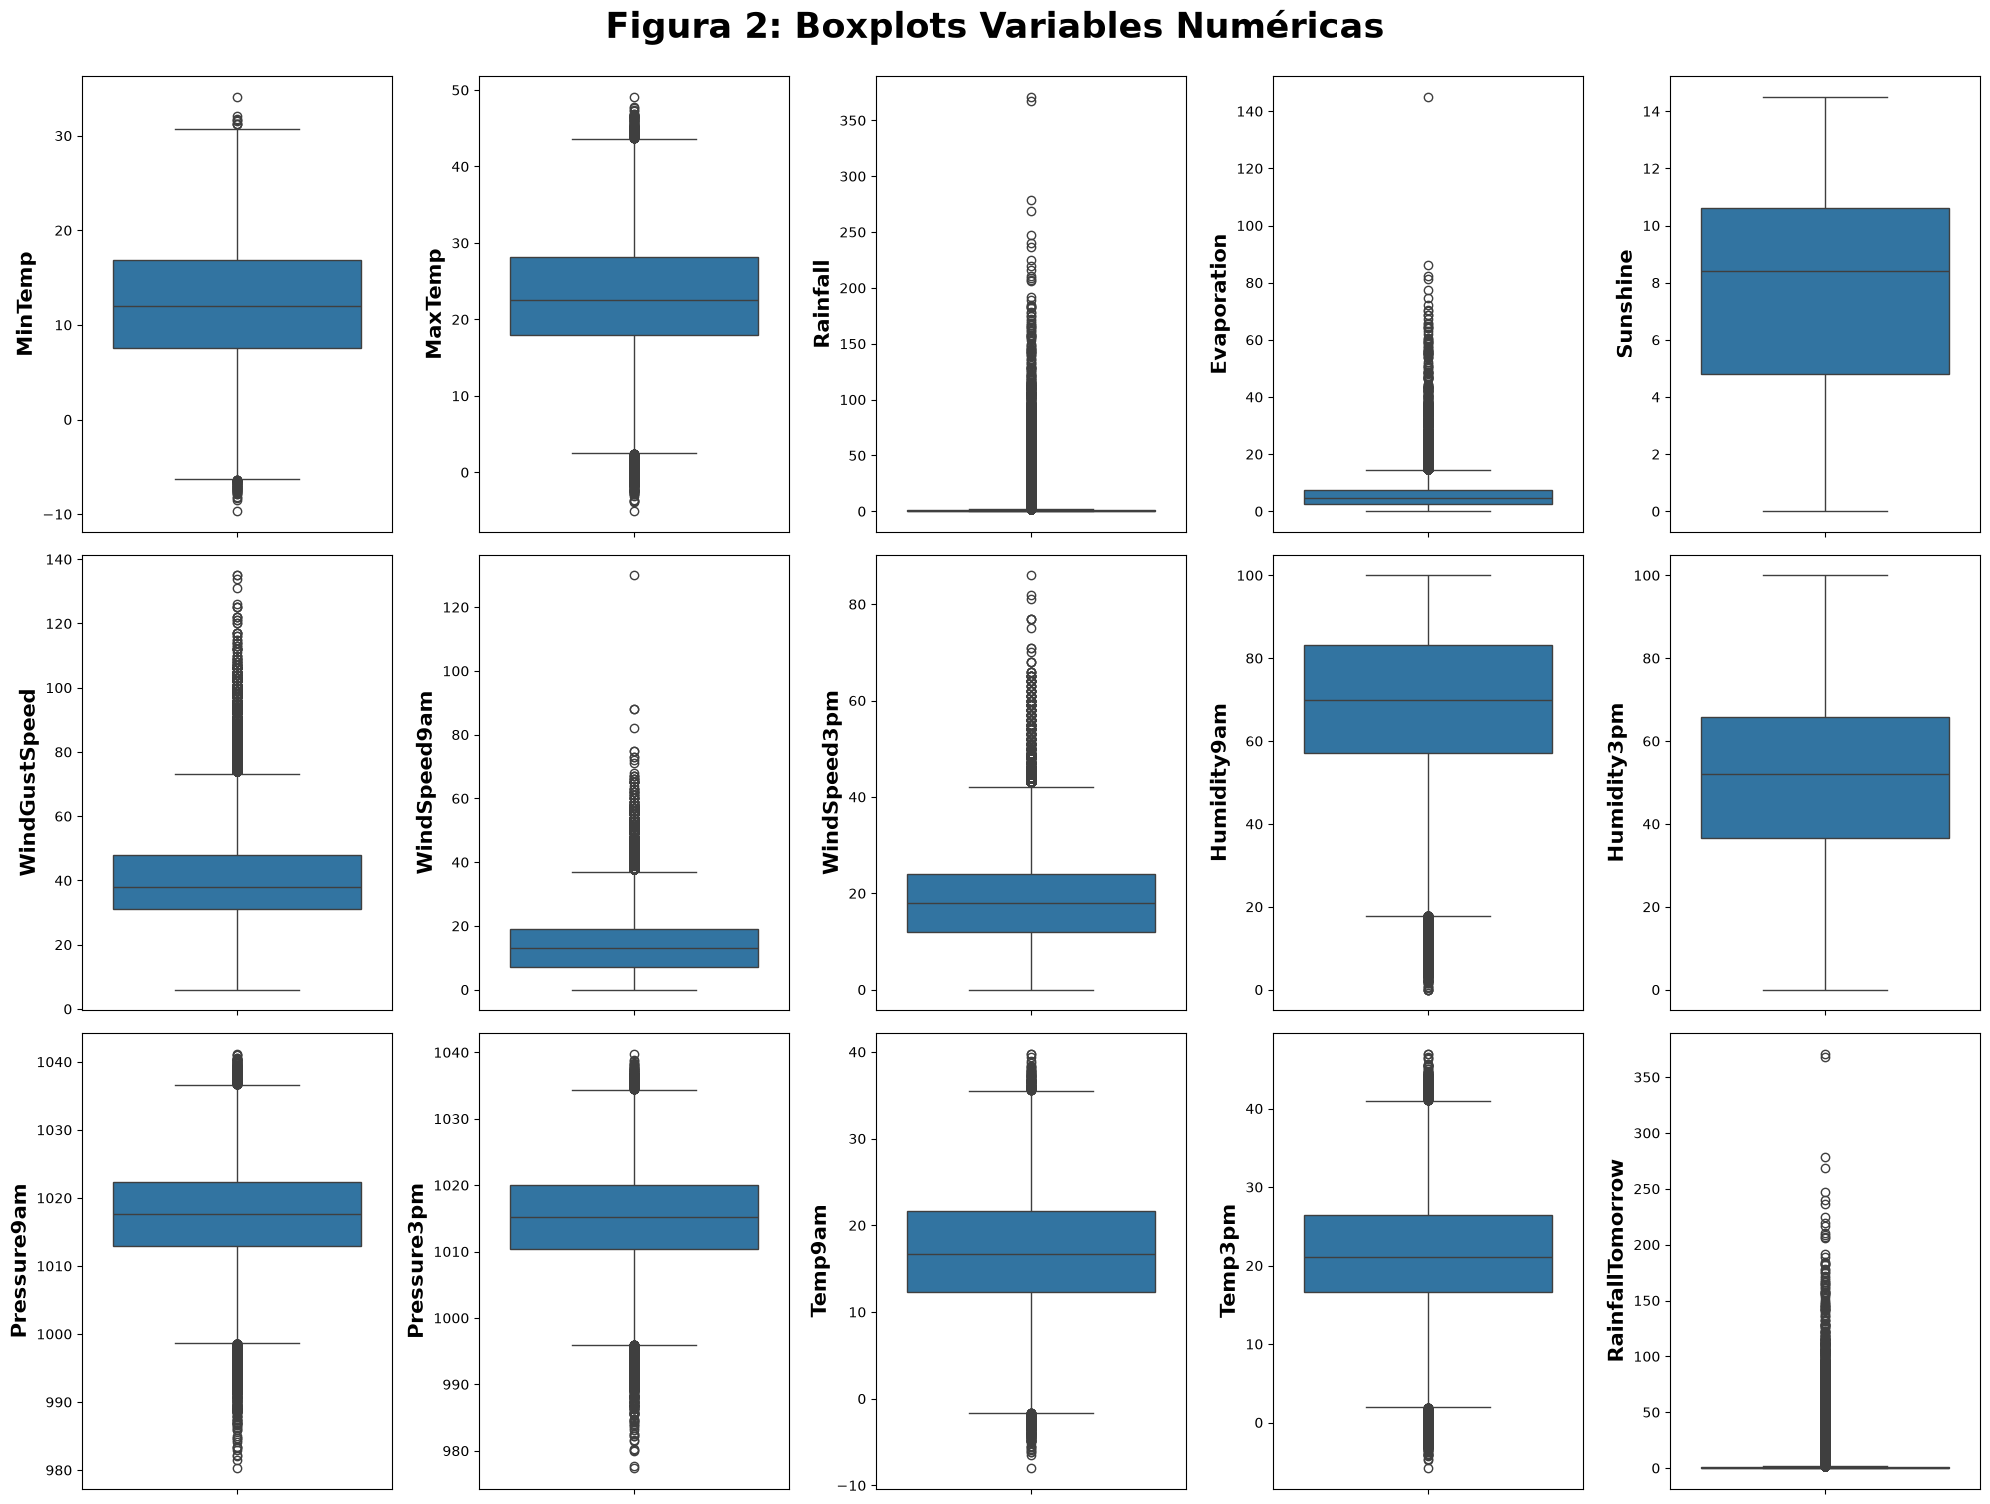

In [17]:
fig, axes = plt.subplots(ncols=5, nrows=3, figsize=(20, 15))
axes = axes.flatten()

for ax, columna in zip(axes, columnas_num.columns):
    sns.boxplot(columnas_num, y=columna, ax=ax)
    ax.set_ylabel(columna, fontweight = 'bold', fontsize = 15)

for i in range(len(columnas_num.columns), len(axes)):
    axes[i].set_visible(False)

fig.suptitle('Figura 2: Boxplots Variables Numéricas', fontweight = 'bold', fontsize = 25, y=1)
plt.tight_layout()
plt.show()

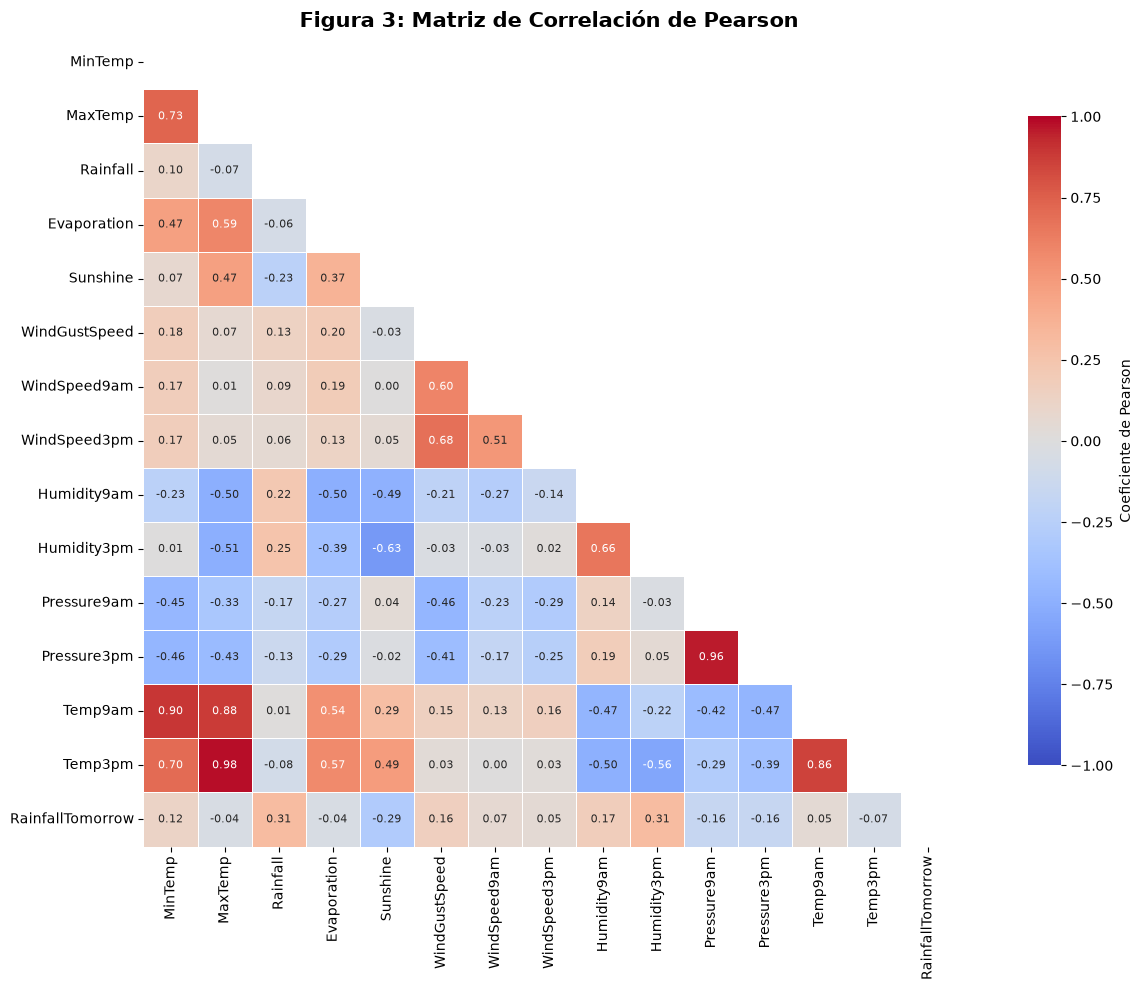

In [35]:
matriz_correlacion = columnas_num.corr(method = 'pearson')
mascara = np.triu(np.ones_like(matriz_correlacion, dtype = bool))

fig, ax = plt.subplots(figsize = (15, 10))

sns.heatmap(matriz_correlacion, mask = mascara, annot = True, fmt = '.2f',
            annot_kws = {'size' : 8}, cmap = 'coolwarm', vmin = -1, vmax = 1,
            center = 0, square = True, linewidths = 0.5,
            cbar_kws = {'shrink' : 0.8, 'label' : 'Coeficiente de Pearson'}, ax = ax)

ax.set_title('Figura 3: Matriz de Correlación de Pearson', fontweight = 'bold', fontsize = 15, y=1)
plt.tight_layout()
plt.show()

## Análisis de Datos Faltantes

In [ ]:
print(f"Cantidad de nulos por {clima_aus.isna().sum()}.")
print(f"\n Cantidad de nulos en el Dataset {clima_aus.isna().sum().sum()}.")

Cantidad de nulos por Date                    0
Location                0
MinTemp              1484
MaxTemp              1253
Rainfall             3260
Evaporation         62754
Sunshine            69796
WindGustDir         10316
WindGustSpeed       10253
WindDir9am          10562
WindDir3pm           4226
WindSpeed9am         1767
WindSpeed3pm         3061
Humidity9am          2653
Humidity3pm          4505
Pressure9am         15061
Pressure3pm         15024
Cloud9am            55870
Cloud3pm            59336
Temp9am              1766
Temp3pm              3607
RainToday            3260
RainTomorrow         3259
RainfallTomorrow     3259
dtype: int64.

 Cantidad de nulos en el Dataset 346332.


In [ ]:
clima_aus